---
# HMM OT - Pipeline
---

## Imports

In [2]:
# Standard library
import os
import glob
from pathlib import Path
from itertools import groupby
from functools import partial

# Utilities
from joblib import Parallel, delayed, parallel_config, effective_n_jobs
from tqdm import tqdm

# Numerics - data
import numpy as np
import pandas as pd

# Plotting
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.patches as mpatches
from matplotlib.patches import Ellipse
from matplotlib.colors import ListedColormap, BoundaryNorm
from cycler import cycler
import seaborn as sns

# Stats - signal
import scipy.stats as stats
from scipy.stats import zscore, spearmanr, mannwhitneyu, chi2
from scipy.signal import welch

# Statsmodels
import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from statsmodels.miscmodels.ordinal_model import OrderedModel

# Statistical annotations
from statannotations.Annotator import Annotator

# Machine learning
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.manifold import MDS
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import silhouette_score

# HMM
import jax
import jax.random as jr
import jax.numpy as jnp
from jax import vmap
from dynamax.hidden_markov_model import GaussianHMM
from dynamax.hidden_markov_model.models.gaussian_hmm import GaussianHMMEmissions, ParamsGaussianHMMEmissions
from dynamax.parameters import ParameterProperties
from dynamax.utils.bijectors import RealToPSDBijector
from dynamax.utils.distributions import InverseWishart
from dynamax.utils.utils import pytree_sum

# OT
import ot

## fMRI Utils

In [17]:
def load_fMRI(data_root, file_pattern):
    '''
    Load fMRI time series from a BIDS-like directory tree.
    '''
    data, subjects = [], []
    errors = 0

    subs = sorted(d for d in os.listdir(data_root) if os.path.isdir(os.path.join(data_root, d)) and d.startswith("sub-"))

    for sub in subs:
        sub_path = os.path.join(data_root, sub)
        sessions = sorted(s for s in os.listdir(sub_path) if os.path.isdir(os.path.join(sub_path, s)) and s.startswith("ses-"))

        for ses in sessions:
            func_dir = os.path.join(sub_path, ses, "func")
            if not os.path.isdir(func_dir):
                continue

            matched = sorted(glob.glob(os.path.join(func_dir, file_pattern)))

            for fp in matched:
                try:
                    data.append(pd.read_csv(fp, sep="\t").values)
                    subjects.append(f"{sub}_{ses}")
                except Exception as e:
                    print(f"Error loading {fp}: {e}")
                    errors += 1

    if data:
        print(f"Loaded {len(data)} subjects with shape {data[0].shape}")
    else:
        print("Loaded 0 subjects")

    if errors:
        print(f"Errors: {errors}")

    return np.asarray(data), np.asarray(subjects)


def zscore_fmri(fmri_data):
    '''
    Z-score each parcel across time.
    '''
    return np.asarray([zscore(subject_data, axis=1) for subject_data in fmri_data])


def compute_pca(X, n_components=None):
    '''
    Fit PCA to a samples-by-features matrix.
    '''
    pca = PCA(n_components=n_components, svd_solver="full")
    projections = pca.fit_transform(X)
    return projections, pca.explained_variance_ratio_, pca.components_

## HMM Utils

In [18]:
class ZeroMeanGaussianHMMEmissions(GaussianHMMEmissions):
    def __init__(self, num_states, emission_dim, emission_prior_scale=1e-4,
                 emission_prior_extra_df=0.1, init_jitter=1e-4):

        super().__init__(
            num_states=num_states,
            emission_dim=emission_dim,
            emission_prior_mean=0.0,
            emission_prior_concentration=1e-4,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
        )

        self.init_jitter = float(init_jitter)

    def initialize(self, key=jr.PRNGKey(0), method="prior", emission_means=None,
                   emission_covariances=None, emissions=None):

        if emission_means is not None and not np.allclose(np.asarray(emission_means), 0.0):
            raise ValueError("ZeroMeanGaussianHMM requires emission_means = 0")

        if emission_covariances is not None:
            covs = jnp.asarray(emission_covariances)

        elif method.lower() == "kmeans":
            if emissions is None:
                raise ValueError("emissions are required for k-means initialization")

            X = np.asarray(emissions).reshape(-1, self.emission_dim)
            seed = int(jr.randint(key, (), 0, 2**31 - 1))
            labels = KMeans(n_clusters=self.num_states, n_init=10, random_state=seed).fit_predict(X)

            # Global uncentred second moment, used as fallback
            global_cov = X.T @ X / X.shape[0]
            eye = np.eye(self.emission_dim)
            covs = []

            for k in range(self.num_states):
                Xk = X[labels == k]
                cov_k = Xk.T @ Xk / len(Xk) if len(Xk) > self.emission_dim else global_cov.copy()
                cov_k = 0.5 * (cov_k + cov_k.T)
                cov_k += self.init_jitter * eye
                covs.append(cov_k)

            covs = jnp.asarray(covs)

        elif method.lower() == "prior":
            prior = InverseWishart(self.emission_prior_df, self.emission_prior_scale)
            covs = prior.sample(seed=key, sample_shape=(self.num_states,))

        else:
            raise ValueError(f"Unknown initialization method: {method}")

        params = ParamsGaussianHMMEmissions(
            means=jnp.zeros((self.num_states, self.emission_dim)),
            covs=covs,
        )

        props = ParamsGaussianHMMEmissions(
            means=ParameterProperties(trainable=False),
            covs=ParameterProperties(constrainer=RealToPSDBijector()),
        )

        return params, props

    def log_prior(self, params):
        prior = InverseWishart(self.emission_prior_df, self.emission_prior_scale)
        return prior.log_prob(params.covs).sum()

    def m_step(self, params, props, batch_stats, m_step_state):
        stats = pytree_sum(batch_stats, axis=0)
        sum_w = stats["sum_w"]
        sum_xxT = stats["sum_xxT"]

        # Fixed-mean posterior
        post_df = self.emission_prior_df + sum_w
        post_scale = self.emission_prior_scale[None, :, :] + sum_xxT
        covs = post_scale / (post_df[:, None, None] + self.emission_dim + 1)
        covs = 0.5 * (covs + jnp.swapaxes(covs, -1, -2))

        params = params._replace(means=jnp.zeros_like(params.means), covs=covs)
        return params, m_step_state


class ZeroMeanGaussianHMM(GaussianHMM):
    def __init__(self, num_states, emission_dim, initial_probs_concentration=1.1,
                 transition_matrix_concentration=1.1, transition_matrix_stickiness=0.0,
                 emission_prior_scale=1e-4, emission_prior_extra_df=0.1, init_jitter=1e-4):

        super().__init__(
            num_states=num_states,
            emission_dim=emission_dim,
            initial_probs_concentration=initial_probs_concentration,
            transition_matrix_concentration=transition_matrix_concentration,
            transition_matrix_stickiness=transition_matrix_stickiness,
            emission_prior_mean=0.0,
            emission_prior_concentration=1e-4,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
        )

        self.emission_component = ZeroMeanGaussianHMMEmissions(
            num_states=num_states,
            emission_dim=emission_dim,
            emission_prior_scale=emission_prior_scale,
            emission_prior_extra_df=emission_prior_extra_df,
            init_jitter=init_jitter,
        )


def num_params_gaussian_hmm(K, D, zero_mean=True):
    '''
    Number of free parameters in a K-state Gaussian HMM with D-dimensional full-covariance emissions.
    '''
    init_probs = K - 1
    transitions = K * (K - 1)
    covariances = K * D * (D + 1) // 2
    means = 0 if zero_mean else K * D

    return init_probs + transitions + covariances + means


def hmm_data_ll(hmm, params, emissions):
    '''
    Marginal data log-likelihood summed over independent subject sequences.
    '''
    seq_lls = vmap(partial(hmm.marginal_log_prob, params))(emissions)
    return float(seq_lls.sum())


def fit_hmm_restarts(emissions, n_states, n_iter=300, n_restarts=20, random_state=None,
                     zero_mean=True, n_jobs=1, backend="loky", verbose=False):
    '''
    Fit a full-covariance Gaussian HMM with independent parallel restarts.
    '''
    emissions_np = np.asarray(emissions)
    emission_dim = emissions_np.shape[2]

    rng = np.random.default_rng(random_state)
    seeds = [int(rng.integers(0, int(1e6))) for _ in range(n_restarts)]

    if n_jobs == -1:
        n_jobs_use = min(n_restarts, effective_n_jobs(-1))
    elif n_jobs < 1:
        raise ValueError("n_jobs must be -1 or a positive integer")
    else:
        n_jobs_use = min(int(n_jobs), n_restarts, effective_n_jobs(-1))

    if n_jobs_use == 1:
        generator = (
            fit_hmm_restart_worker(emissions_np, n_states, n_iter, seed, zero_mean, restart)
            for restart, seed in enumerate(seeds)
        )
        results = list(tqdm(generator, total=n_restarts, desc="HMM restarts", disable=not verbose))

    else:
        with parallel_config(backend=backend, n_jobs=n_jobs_use, inner_max_num_threads=1):
            generator = Parallel(return_as="generator_unordered", batch_size=1, max_nbytes="1M", mmap_mode="r")(
                delayed(fit_hmm_restart_worker)(emissions_np, n_states, n_iter, seed, zero_mean, restart)
                for restart, seed in enumerate(seeds)
            )
            results = list(tqdm(generator, total=n_restarts, desc=f"HMM restarts ({n_jobs_use} workers)",
                                disable=not verbose))

    results = sorted(results, key=lambda r: r["restart"])

    if len(results) != n_restarts:
        raise RuntimeError(f"Expected {n_restarts} completed restarts, found {len(results)}")
    if not all(np.isfinite(r["ll_data"]) for r in results):
        raise RuntimeError("At least one restart returned a non-finite log-likelihood")

    best = max(results, key=lambda r: r["ll_data"])
    best_hmm = ZeroMeanGaussianHMM(n_states, emission_dim) if zero_mean else GaussianHMM(n_states, emission_dim)
    _, best_props = best_hmm.initialize(key=jax.random.PRNGKey(best["seed"]), method="prior")

    best_params = jax.tree_util.tree_map(jnp.asarray, best["params"])
    best_lls = [float(x) for x in best["lls"]]
    best_seed = int(best["seed"])
    best_ll = float(best["ll_data"])

    rows = [
        {key: result[key] for key in ["restart", "seed", "zero_mean", "ll_data", "fit_em_last"]}
        for result in results
    ]

    return best_hmm, best_params, best_props, best_lls, best_seed, best_ll, rows
    
def fit_hmm_restart_worker(emissions_np, n_states, n_iter, seed, zero_mean, restart):
    '''
    Fit one Gaussian HMM restart in an independent process.
    '''
    emissions = jnp.asarray(emissions_np)
    hmm = ZeroMeanGaussianHMM(n_states, emissions.shape[2]) if zero_mean else GaussianHMM(n_states, emissions.shape[2])

    params, props = hmm.initialize(key=jax.random.PRNGKey(seed), method="kmeans", emissions=emissions)
    params, lls = hmm.fit_em(params, props, emissions, num_iters=n_iter, verbose=False)
    ll_data = hmm_data_ll(hmm, params, emissions)

    return {
        "restart": restart,
        "seed": seed,
        "zero_mean": zero_mean,
        "ll_data": ll_data,
        "fit_em_last": float(lls[-1]),
        "params": jax.device_get(params),
        "lls": np.asarray(jax.device_get(lls), dtype=float),
    }

    
def save_hmm_fit(out_dir, df_final_fit, best_params, best_lls):
    '''
    Save the selected HMM fit and restart results.
    '''
    out_dir = Path(out_dir)
    out_dir.mkdir(parents=True, exist_ok=True)

    df_final_fit.to_csv(out_dir / "hmm_restart_table.csv", index=False)
    np.save(out_dir / "hmm_em_trace.npy", np.asarray(best_lls, dtype=float))
    np.savez_compressed(
        out_dir / "hmm_parameters.npz",
        initial_probs=np.asarray(best_params.initial.probs),
        transition_matrix=np.asarray(best_params.transitions.transition_matrix),
        means=np.asarray(best_params.emissions.means),
        covs=np.asarray(best_params.emissions.covs),
    )


def compute_posteriors_subjectwise(best_hmm, best_params, emissions, T=None, return_flat=True):
    '''
    Compute smoothed probabilities and Viterbi paths independently for each subject.
    '''
    emissions = jnp.asarray(emissions)

    if emissions.ndim != 3:
        raise ValueError("emissions must have shape: subjects x time x features")

    n_subjects, n_time, _ = emissions.shape

    if T is not None and n_time != T:
        raise ValueError(f"emissions has T={n_time}, but requested T={T}")

    gamma_list = []
    path_list = []

    for s in range(n_subjects):
        em_s = emissions[s]

        post_s = best_hmm.smoother(best_params, em_s)
        gamma_s = np.asarray(post_s.smoothed_probs)
        path_s = np.asarray(best_hmm.most_likely_states(best_params, em_s))

        gamma_list.append(gamma_s)
        path_list.append(path_s)

    gamma_seq = np.stack(gamma_list, axis=0)  # subjects x time x K
    path_seq = np.stack(path_list, axis=0)    # subjects x time

    if return_flat:
        gamma_all = gamma_seq.reshape(n_subjects * n_time, gamma_seq.shape[-1])
        path_all = path_seq.reshape(n_subjects * n_time)
        return gamma_all, path_all

    return gamma_seq, path_seq


def backproject_hmm_parameters(best_params, eigenvectors, n_components):
    '''
    Back-project HMM means and covariances from PCA space to parcel space.
    '''
    U = np.asarray(eigenvectors[:n_components, :])

    means_pca = np.asarray(best_params.emissions.means)
    covs_pca = np.asarray(best_params.emissions.covs)

    means_orig = means_pca @ U

    covs_orig = []

    for k in range(covs_pca.shape[0]):
        cov_orig = U.T @ covs_pca[k] @ U
        cov_orig = 0.5 * (cov_orig + cov_orig.T)
        covs_orig.append(cov_orig)

    covs_orig = np.stack(covs_orig)

    vars_orig = np.diagonal(covs_orig, axis1=1, axis2=2)

    if vars_orig.min() < -1e-8:
        raise ValueError(
            f"Negative reconstructed variance: {vars_orig.min()}"
        )

    stds_orig = np.sqrt(np.clip(vars_orig, 0, None))
    denom = stds_orig[:, :, None] * stds_orig[:, None, :]

    fcs_orig = np.divide(covs_orig, denom, out=np.zeros_like(covs_orig), where=denom > 0)
    fcs_orig = np.clip(fcs_orig, -1, 1)

    diagonal = np.arange(fcs_orig.shape[1])
    fcs_orig[:, diagonal, diagonal] = 1.0

    return {
        "means_orig": means_orig,
        "covs_orig": covs_orig,
        "fcs_orig": fcs_orig,
    }


def reconstruct_hmm_fc(gamma_seq, means_orig, covs_orig, zero_mean):
    '''
    Reconstruct the global FC from the HMM marginal mixture using empirical state occupancies.
    '''
    alpha_k = np.asarray(gamma_seq).mean(axis=(0, 1))
    n_states = len(alpha_k)

    if zero_mean:
        mu_mix = np.zeros(means_orig.shape[1])
        cov_mix = sum(alpha_k[k] * covs_orig[k] for k in range(n_states))
    else:
        mu_mix = np.sum(alpha_k[:, None] * means_orig, axis=0)
        cov_mix = sum(
            alpha_k[k] * (covs_orig[k] + np.outer(means_orig[k], means_orig[k]))
            for k in range(n_states)
        ) - np.outer(mu_mix, mu_mix)

    stds = np.sqrt(np.diag(cov_mix))
    fc_reconstructed = cov_mix / np.outer(stds, stds)

    return fc_reconstructed

    
def build_hmm_metrics(gamma_all, path_all, subjects, df_sel, T, TR):
    '''
    Build subject/state-level HMM metrics (Fractional Occupancy, Dwell TIme, Switch Rate).
    '''
    gamma_all = np.asarray(gamma_all, dtype=float)
    path_all = np.asarray(path_all, dtype=int)

    n_subjects = len(subjects)

    if gamma_all.ndim == 2:
        K = gamma_all.shape[1]
        gamma_seq = gamma_all.reshape(n_subjects, T, K)
    elif gamma_all.ndim == 3:
        gamma_seq = gamma_all
        K = gamma_seq.shape[2]
    else:
        raise ValueError("gamma_all must be 2D or 3D")

    if path_all.ndim == 1:
        path_seq = path_all.reshape(n_subjects, T)
    elif path_all.ndim == 2:
        path_seq = path_all
    else:
        raise ValueError("path_all must be 1D or 2D")

    records = []

    for s, pid in enumerate(subjects):

        gamma = gamma_seq[s]
        path = path_seq[s]

        switch_rate = np.mean(path[1:] != path[:-1])
        group = df_sel.loc[pid, "group"]

        for k in range(K):
            fo_soft = gamma[:, k].mean()
            fo_hard = np.mean(path == k)

            runs = [len(list(g)) for st, g in groupby(path) if st == k]
            dwell = np.mean(runs) * TR if runs else 0.0

            records.append({
                "participant_id": pid,
                "Group": group,
                "State": f"State{k}",
                "FO_soft": fo_soft,
                "FO_hard": fo_hard,
                "Dwell": dwell,
                "SwitchRate": switch_rate,
            })

    return pd.DataFrame.from_records(records)

## OT Utils

In [19]:
def compute_transition_matrices_dynamax(best_hmm, best_params, emissions):
    '''
    Compute joint transition probability matrices from posterior transition probabilities.
    '''
    emissions = jnp.asarray(emissions)

    if emissions.ndim != 3:
        raise ValueError("emissions must have shape: subjects x time x features")

    N_subjects = emissions.shape[0]
    Q_all = []

    for s in range(N_subjects):
        em_s = emissions[s]

        post_s = best_hmm.smoother(best_params, em_s)
        trans = np.asarray(post_s.trans_probs)

        if trans.ndim != 2:
            raise ValueError(f"Expected post_s.trans_probs with shape (K, K),"
                             f"got shape {trans.shape} for subject {s}")

        if trans.sum() <= 0:
            raise ValueError(f"Transition matrix has non-positive sum for subject {s}")

        Q = trans / trans.sum()  # joint P(i,j) 
        Q_all.append(Q)

    return np.asarray(Q_all)


def f(G):
    G = np.maximum(G, 1e-15)
    return np.sum(G * np.log(G))


def df(G):
    G = np.maximum(G, 1e-15)
    return np.log(G) + 1.0


def kl(P, Q):
    '''
    Compute KL divergence.
    '''
    P = np.maximum(P, 1e-15)
    Q = np.maximum(Q, 1e-15)

    P = P / P.sum()
    Q = Q / Q.sum()

    return np.sum(P * (np.log(P) - np.log(Q)))


def compute_sb_costs_parallel(Q_all, eps=1.0, n_jobs=-1, backend="loky"):
    '''
    Parallel version of compute_sb_costs.
    '''
    Q_all = np.asarray(Q_all, dtype=float)

    Q_use = np.maximum(Q_all, 1e-15)
    Q_use = Q_use / Q_use.sum(axis=(1, 2), keepdims=True)

    pi_source_all = Q_use.sum(axis=2)  # row marginals: pre-transition occupancy
    pi_target_all = Q_use.sum(axis=1)  # column marginals: post-transition occupancy

    N = len(Q_use)

    def _compute_row(i):
        row = np.zeros(N, dtype=float)

        Q_i = Q_use[i]
        M = -np.log(Q_i)
        a = pi_source_all[i]

        for j in range(N):
            b = pi_target_all[j]
            P = ot.optim.cg(a, b, M, eps, f, df, verbose=False)
            row[j] = kl(P, Q_i) + (eps - 1.0) * f(P)

        return row

    rows = Parallel(n_jobs=n_jobs, backend=backend)(
        delayed(_compute_row)(i) for i in tqdm(range(N), desc="SB costs")
    )

    return np.vstack(rows), pi_source_all, pi_target_all, Q_use


def cluster_ms_ot(C_dir, subjects, df_sel, n_clusters=2, mds_random_state=23):
    '''
    Cluster MS subjects from the symmetrized OT cost and compute the MDS embedding.
    '''
    C_full = np.asarray(C_dir)

    C_sym = 0.5 * (C_full + C_full.T)
    np.fill_diagonal(C_sym, 0.0)

    groups = df_sel.loc[subjects, "group"].astype(str).str.upper().to_numpy()
    ms_mask = groups == "MS"
    ms_idx = np.where(ms_mask)[0]
    subjects_ms = np.asarray(subjects)[ms_mask]

    C_ms = C_sym[np.ix_(ms_idx, ms_idx)]

    model = AgglomerativeClustering(n_clusters=n_clusters, metric="precomputed", linkage="average")
    labels_ms = model.fit_predict(C_ms).astype(int)

    mds = MDS(n_components=2, dissimilarity="precomputed",
              random_state=mds_random_state, n_init=10, max_iter=300)
    emb = mds.fit_transform(C_ms)

    ms_df = df_sel.loc[subjects_ms].copy().reset_index()
    ms_df["OT_cluster"] = labels_ms.astype(int)
    ms_df["OT_dim1"] = emb[:, 0]
    ms_df["OT_dim2"] = emb[:, 1]

    return ms_df[["participant_id", "OT_cluster", "OT_dim1", "OT_dim2"]].copy()

## Pipeline Utils

In [22]:
def make_config_dir(out_dir, M, K, zero_mean, overwrite=False):
    '''
    Create the output directory for one HMM-OT configuration.
    '''
    model_name = "zeromean" if zero_mean else "freemean"
    run_dir = Path(out_dir) / f"M{M}_K{K:02d}" / model_name

    if run_dir.exists() and any(run_dir.iterdir()) and not overwrite:
        raise FileExistsError(f"Output directory already contains files: {run_dir}")

    run_dir.mkdir(parents=True, exist_ok=True)
    return run_dir


def save_configuration_outputs(run_dir, gamma_seq, path_seq, df_hmm, state_params,
                               fc_reconstructed, Q_all, C_dir, df_clusters):
    '''
    Save the numerical outputs for one HMM-OT configuration.
    '''
    run_dir = Path(run_dir)

    np.save(run_dir / "gamma_seq.npy", gamma_seq)
    np.save(run_dir / "path_seq.npy", path_seq)

    df_hmm.to_csv(run_dir / "hmm_metrics.csv", index=False)

    np.save(run_dir / "means_orig.npy", state_params["means_orig"])
    np.save(run_dir / "covs_orig.npy", state_params["covs_orig"])
    np.save(run_dir / "fcs_orig.npy", state_params["fcs_orig"])
    np.save(run_dir / "hmm_reconstructed_fc.npy", fc_reconstructed)

    np.save(run_dir / "Q_all.npy", Q_all)
    np.save(run_dir / "cost_matrix_dir.npy", C_dir)

    df_clusters.to_csv(run_dir / "clusters_assignment.csv", index=False)


def run_configuration(projections_seq, eigenvectors, subjects, df_sel, TR, out_dir,
                      M, K, zero_mean, n_iter=200, n_restarts=20, random_state=23,
                      n_jobs_hmm=20, hmm_backend="loky", n_jobs_ot=32, ot_backend="loky",
                      overwrite=False, verbose=False):
    '''
    Run and save one HMM-OT configuration.
    '''
    run_dir = make_config_dir(out_dir, M, K, zero_mean, overwrite=overwrite)

    n_time = projections_seq.shape[1]
    emissions = jnp.asarray(projections_seq[:, :, :M])

    run_seed = random_state + 1000 * M + K + (1_000_000 if not zero_mean else 0)

    best_hmm, best_params, _, best_lls, _, _, rows = fit_hmm_restarts(
        emissions, n_states=K, n_iter=n_iter, n_restarts=n_restarts, random_state=run_seed,
        zero_mean=zero_mean, n_jobs=n_jobs_hmm, backend=hmm_backend, verbose=verbose
    )

    df_final_fit = pd.DataFrame(rows)
    save_hmm_fit(run_dir, df_final_fit, best_params, best_lls)

    gamma_seq, path_seq = compute_posteriors_subjectwise(
        best_hmm, best_params, emissions, T=n_time, return_flat=False
    )
    gamma_seq = np.asarray(gamma_seq)
    path_seq = np.asarray(path_seq)

    state_params = backproject_hmm_parameters(best_params, eigenvectors, M)

    fc_reconstructed = reconstruct_hmm_fc(
        gamma_seq, state_params["means_orig"], state_params["covs_orig"], zero_mean
    )

    df_hmm = build_hmm_metrics(gamma_seq, path_seq, subjects, df_sel, n_time, TR)

    Q_all = compute_transition_matrices_dynamax(
        best_hmm=best_hmm, best_params=best_params, emissions=emissions
    )

    C_dir, _, _, _ = compute_sb_costs_parallel(
        Q_all=Q_all, n_jobs=n_jobs_ot, backend=ot_backend
    )

    df_clusters = cluster_ms_ot(
        C_dir, subjects, df_sel, n_clusters=2, mds_random_state=23
    )

    save_configuration_outputs(
        run_dir, gamma_seq, path_seq, df_hmm, state_params,
        fc_reconstructed, Q_all, C_dir, df_clusters
    )

    return run_dir


def run_pipeline(projections_seq, eigenvectors, subjects, df_sel, TR, out_dir,
                 M_values, K_values, zero_mean_values=(True, False),
                 n_iter=200, n_restarts=20, random_state=23,
                 n_jobs_hmm=20, hmm_backend="loky", n_jobs_ot=32, ot_backend="loky",
                 overwrite=False, verbose=False):
    '''
    Run the HMM-OT pipeline across model configurations.
    '''
    run_dirs = []

    for zero_mean in zero_mean_values:
        for M in M_values:
            for K in K_values:
                model_name = "zeromean" if zero_mean else "freemean"
                print(f"Running M={M}, K={K}, {model_name}")

                run_dir = run_configuration(
                    projections_seq, eigenvectors, subjects, df_sel, TR, out_dir,
                    M=M, K=K, zero_mean=zero_mean, n_iter=n_iter, n_restarts=n_restarts,
                    random_state=random_state, n_jobs_hmm=n_jobs_hmm, hmm_backend=hmm_backend,
                    n_jobs_ot=n_jobs_ot, ot_backend=ot_backend,
                    overwrite=overwrite, verbose=verbose
                )

                run_dirs.append(run_dir)

    return run_dirs

## Plotting Utils

In [23]:
def plot_matrices(matrices, network_labels=None, network_names=None, titles=None, vminvmax=[[-1, 1]], center=None, cmap='RdBu_r',
                  figsize_per_matrix=(5, 4), sort=True, labels_for=None, dataset=None, label_pad_x=1.5, label_pad_y=1.5,
                  label_size=3.0, x_label_shift=0.0, y_label_shift=0.0, axes=None):
    '''
    Plot one or more matrices (FC) with optional network labels.
    '''
    if dataset is not None:
        network_labels = dataset.network_labels
        network_names = dataset.network_names

    num_matrices = len(matrices)

    # Create axes
    if axes is None:
        fig, axes = plt.subplots(1, num_matrices, figsize=(figsize_per_matrix[0] * num_matrices, figsize_per_matrix[1]),
                                 constrained_layout=True)
        if num_matrices == 1:
            axes = [axes]
    else:
        if num_matrices == 1:
            axes = [axes] if not isinstance(axes, (list, tuple, np.ndarray)) else list(np.ravel(axes))
        else:
            axes = list(np.ravel(axes))

    labels_available = (network_labels is not None) and (network_names is not None)

    # Select matrices with labels
    if labels_for is None:
        label_mask = [True] * num_matrices
    else:
        if isinstance(labels_for, (list, tuple)) and len(labels_for) == num_matrices and all(isinstance(x, (bool, np.bool_)) for x in labels_for):
            label_mask = list(labels_for)
        else:
            label_mask = [False] * num_matrices
            for idx in labels_for:
                label_mask[int(idx)] = True

    tick_positions, label_positions, tick_labels = [], [], []

    # Prepare network labels
    if labels_available:
        network_labels = np.array(network_labels)
        network_names = list(network_names)  # type: ignore

        if sort:
            _, sorted_labels = np.unique(network_labels, return_inverse=True)
            sorted_indices = np.argsort(sorted_labels, kind='stable')
            labels_sorted = sorted_labels[sorted_indices]
        else:
            sorted_indices = np.arange(len(network_labels))
            labels_sorted = network_labels

        prev_label = labels_sorted[0]
        start = 0
        tick_positions.append(0)

        for j, label in enumerate(labels_sorted):
            if label != prev_label:
                tick_positions.append(j)
                label_positions.append((start + j) / 2)
                tick_labels.append(network_names[prev_label])
                start = j
                prev_label = label

        tick_positions.append(len(labels_sorted))
        label_positions.append((start + len(labels_sorted)) / 2)
        tick_labels.append(network_names[prev_label])
    else:
        sorted_indices = None

    tick_positions = sorted(list(set(tick_positions)))
    label_fontsize = max(6, min(12, figsize_per_matrix[0] * label_size))

    # Plot matrices
    for i, (matrix, ax) in enumerate(zip(matrices, axes)):
        if labels_available and sort:
            mat_to_plot = matrix[np.ix_(sorted_indices, sorted_indices)]  # type: ignore
        else:
            mat_to_plot = matrix

        vmin = vminvmax[i][0]
        vmax = vminvmax[i][1]
        heatmap = sns.heatmap(mat_to_plot, ax=ax, cmap=cmap, center=center, vmin=vmin, vmax=vmax, square=True,
                              xticklabels=False, yticklabels=False, cbar=True, cbar_kws={'shrink': 1, 'pad': 0.05})

        cbar = heatmap.collections[0].colorbar
        if cbar:
            if np.min(mat_to_plot) <= 0:
                cbar.set_ticks([vmin, 0, vmax])
                cbar.set_ticklabels([f"{vmin:.1f}", "0", f"{vmax:.1f}"])
            else:
                cbar.set_ticks([vmin, vmax])
                cbar.set_ticklabels([f"{vmin:.1f}", f"{vmax:.1f}"])

            cbar.outline.set_edgecolor('black')  # type: ignore
            cbar.outline.set_linewidth(0.5)  # type: ignore
            cbar.ax.tick_params(labelsize=10)

        # Add network labels
        if labels_available and label_mask[i]:
            ax.set_xticks(tick_positions)
            ax.set_yticks(tick_positions)
            ax.set_xticklabels([])
            ax.set_yticklabels([])

            for pos, label in zip(label_positions, tick_labels):
                ax.text(pos + x_label_shift, ax.get_ylim()[0] + label_pad_x, label, ha='center', va='top',
                        fontsize=label_fontsize, rotation=90)
                ax.text(ax.get_xlim()[0] - label_pad_y, pos + y_label_shift, label, ha='right', va='center',
                        fontsize=label_fontsize)

        ax.tick_params(axis='both', length=3, width=0.8, labelsize=10)

        if titles and i < len(titles):
            ax.set_title(titles[i], fontsize=14)

        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_edgecolor('black')
            spine.set_linewidth(0.5)
            

def plot_state_means(means, network_labels, network_names, sort=True, cmap="RdBu_r", figsize=(12, 4)):
    '''
    Plot mean BOLD activity for each state grouped by network.
    '''
    means = np.asarray(means, dtype=float)
    network_labels = np.asarray(network_labels)
    network_names = np.asarray(network_names)

    n_states, n_parcels = means.shape

    if len(network_labels) != n_parcels:
        raise ValueError("network_labels and means have incompatible dimensions")

    if sort:
        order = np.argsort(network_labels, kind="stable")
        means_plot = means[:, order]
        labels_plot = network_labels[order]
    else:
        means_plot = means
        labels_plot = network_labels

    boundaries = np.r_[0, np.where(np.diff(labels_plot) != 0)[0] + 1, n_parcels]
    start_inds = boundaries[:-1]
    end_inds = boundaries[1:] - 1
    tick_positions = (start_inds + end_inds) / 2
    tick_labels = [network_names[labels_plot[i]] for i in start_inds]

    vmax = np.nanmax(np.abs(means_plot))

    fig, ax = plt.subplots(figsize=figsize)
    im = ax.imshow(means_plot, aspect="auto", cmap=cmap, vmin=-vmax, vmax=vmax)
    fig.colorbar(im, ax=ax, label="Mean BOLD activity")

    for boundary in boundaries[1:-1]:
        ax.axvline(boundary - 0.5, color="black", lw=1)

    ax.set_xticks(tick_positions)
    ax.set_yticks(np.arange(n_states))
    ax.set_xticklabels(tick_labels)
    ax.set_xlabel("Resting-State Network")
    ax.set_ylabel("State")

    return fig, ax

## Load Data

In [32]:
# fMRI data
DATA_ROOT = Path("/readonly/insights/bids/MS/derivatives/xcp_d")
FILE_PATTERN = "*_space-fsLR_seg-4S156Parcels*_stat-mean_timeseries.tsv"

# Project directories
PROJECT_DIR = Path("/home/taffarello/codes/hmm_ot_project")
DATA_DIR = PROJECT_DIR / "data"
SUPP_DATA_DIR = DATA_DIR / "supp"

# Global parameters
TR = 1.5
T_PER_SUBJ = 240
N_PARCELS = 100
FS = 1.0 / TR

# Parcellization data
network_labels = np.load(DATA_DIR / "network_labels.npy")
network_names = np.load(DATA_DIR / "network_names.npy")

In [33]:
# Load fMRI data
data, subjects = load_fMRI(DATA_ROOT, FILE_PATTERN)

# Prepare cortical BOLD data
bold_all = data.transpose(0, 2, 1)[:, :N_PARCELS, :]
bold_zsc = zscore_fmri(bold_all)

n_subjects, n_parcels, n_time = bold_zsc.shape

if n_parcels != N_PARCELS or n_time != T_PER_SUBJ:
    raise ValueError(f"Unexpected BOLD shape: {bold_all.shape}")

# Load phenotype data
df_sel = pd.read_csv(DATA_DIR / "sel_features.csv", index_col="participant_id")

missing_features = [s for s in subjects if s not in df_sel.index]
if missing_features:
    raise ValueError(f"Missing features for {len(missing_features)} subjects: {missing_features[:10]}")

df_sel = df_sel.loc[subjects].copy()

Loaded 217 subjects with shape (240, 156)


PCA projections sequence shape: (217, 240, 100)


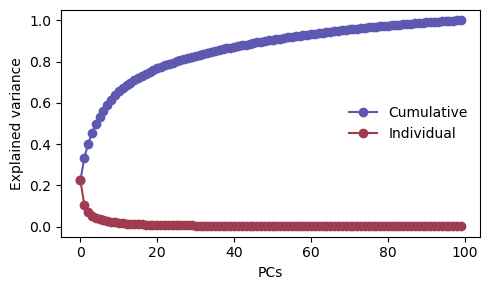

In [34]:
# Reorder data as subjects x time x parcels
X_seq = bold_zsc.transpose(0, 2, 1)

# Stack time across subjects only for PCA
X = X_seq.reshape(n_subjects * n_time, n_parcels)

# PCA across timepoints
projections, explained_variance_ratio, eigenvectors = compute_pca(X, n_components=n_parcels)

# Restore subject boundaries: subjects x time x PCs
n_pcs = projections.shape[1]
projections_seq = projections.reshape(n_subjects, n_time, n_pcs)

print("PCA projections sequence shape:", projections_seq.shape)

# Plot explained variance ratio
colors = plt.cm.twilight(np.linspace(0.3, 0.7, 2))

fig, ax = plt.subplots(figsize=(5, 3))
ax.plot(np.cumsum(explained_variance_ratio), "o-", color=colors[0], label="Cumulative")
ax.plot(explained_variance_ratio, "o-", color=colors[1], label="Individual")
ax.set_xlabel("PCs")
ax.set_ylabel("Explained variance")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Run Configurations

In [ ]:
M_values = [30, 40]
K_values = [3, 4, 5, 6]
zero_mean_values = [True, False]

run_dirs = run_pipeline(
    projections_seq, eigenvectors, subjects, df_sel, TR, SUPP_DATA_DIR,
    M_values=M_values, K_values=K_values, zero_mean_values=zero_mean_values,
    n_iter=200, n_restarts=20, random_state=23,
    n_jobs_hmm=16, n_jobs_ot=16,
    overwrite=False, verbose=True,
)

## Load Results

In [35]:
def load_configuration_results(out_dir, M, K, zero_mean):
    '''
    Load the saved outputs for one HMM-OT configuration.
    '''
    model_name = "zeromean" if zero_mean else "freemean"
    run_dir = Path(out_dir) / f"M{M}_K{K:02d}" / model_name

    results = {
        "run_dir": run_dir,
        "hmm_restart_table": pd.read_csv(run_dir / "hmm_restart_table.csv"),
        "hmm_em_trace": np.load(run_dir / "hmm_em_trace.npy"),
        "gamma_seq": np.load(run_dir / "gamma_seq.npy"),
        "path_seq": np.load(run_dir / "path_seq.npy"),
        "hmm_metrics": pd.read_csv(run_dir / "hmm_metrics.csv"),
        "means_orig": np.load(run_dir / "means_orig.npy"),
        "covs_orig": np.load(run_dir / "covs_orig.npy"),
        "fcs_orig": np.load(run_dir / "fcs_orig.npy"),
        "hmm_reconstructed_fc": np.load(run_dir / "hmm_reconstructed_fc.npy"),
        "Q_all": np.load(run_dir / "Q_all.npy"),
        "cost_matrix_dir": np.load(run_dir / "cost_matrix_dir.npy"),
        "clusters_assignment": pd.read_csv(run_dir / "clusters_assignment.csv"),
    }

    with np.load(run_dir / "hmm_parameters.npz") as data:
        results["hmm_parameters"] = {key: data[key] for key in data.files}

    return results

In [36]:
# Select configuration
m_components = 30
k_states = 3
zero_mean = False 

results = load_configuration_results(SUPP_DATA_DIR, M=m_components, K=k_states, zero_mean=zero_mean)

gamma_seq = results["gamma_seq"]
path_seq = results["path_seq"]
means_orig = results["means_orig"]
covs_orig = results["covs_orig"]
fcs_orig = results["fcs_orig"]
hmm_parameters = results["hmm_parameters"]

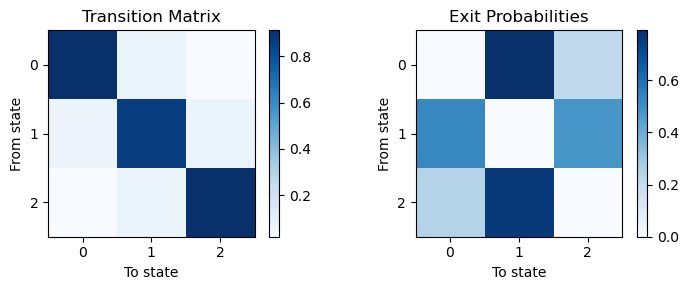

In [37]:
# Estimated transition matrix
A_est = hmm_parameters["transition_matrix"]

# Exit probabilities: remove self-transitions and renormalize rows
A_exit_est = A_est.copy()
np.fill_diagonal(A_exit_est, 0.0)

row_sum = A_exit_est.sum(axis=1, keepdims=True)
A_exit_est = np.divide(A_exit_est, row_sum, out=np.zeros_like(A_exit_est), where=row_sum != 0)

# Plot transition matrices
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3))

im0 = axs[0].imshow(A_est, cmap="Blues")
axs[0].set_title("Transition Matrix")
axs[0].set_xticks(np.arange(k_states))
axs[0].set_yticks(np.arange(k_states))
axs[0].set_xlabel("To state")
axs[0].set_ylabel("From state")
plt.colorbar(im0, ax=axs[0], fraction=0.046)

im1 = axs[1].imshow(A_exit_est, cmap="Blues")
axs[1].set_title("Exit Probabilities")
axs[1].set_xticks(np.arange(k_states))
axs[1].set_yticks(np.arange(k_states))
axs[1].set_xlabel("To state")
axs[1].set_ylabel("From state")
plt.colorbar(im1, ax=axs[1], fraction=0.046)

plt.tight_layout()
plt.show()

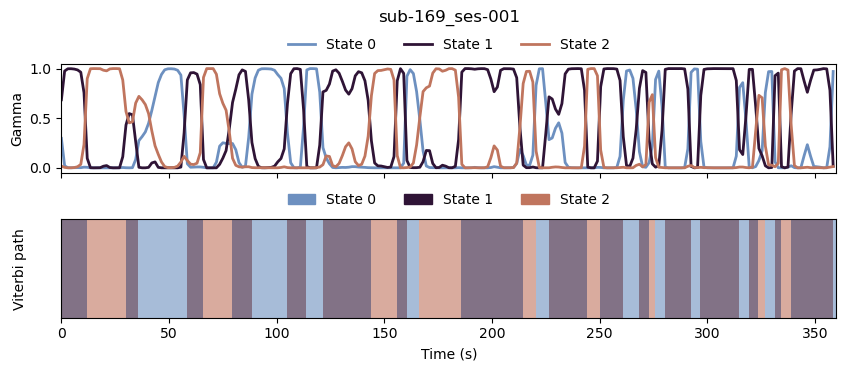

In [40]:
# Plot gamma probabilities and Viterbi path for one subject
sub_idx = np.random.randint(0, n_subjects)
time = np.arange(n_time) * TR

gamma_sub = gamma_seq[sub_idx]
path_sub = path_seq[sub_idx].astype(int)

colors = plt.cm.twilight(np.linspace(0.2, 0.8, k_states))
cmap = ListedColormap(colors)
norm = BoundaryNorm(np.arange(k_states + 1) - 0.5, cmap.N)

fig, axes = plt.subplots(
    2, 1, figsize=(10, 3.3), sharex=True,
    gridspec_kw={"height_ratios": [1.0, 0.9], "hspace": 0.45}
)

axes[0].set_prop_cycle(cycler(color=colors))

for k in range(k_states):
    axes[0].plot(time, gamma_sub[:, k], label=f"State {k}", linewidth=2)

axes[0].set_ylabel("Gamma")
axes[0].set_title(subjects[sub_idx], pad=30)
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, 1.35), ncol=k_states, frameon=False)

axes[1].imshow(
    path_sub[np.newaxis, :], aspect="auto", interpolation="nearest",
    cmap=cmap, norm=norm, extent=[time[0], time[-1] + TR, 0, 1], alpha=0.6
)

handles = [mpatches.Patch(color=colors[k], label=f"State {k}") for k in range(k_states)]
axes[1].legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 1.40),
               ncol=k_states, frameon=False)

axes[1].set_yticks([])
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Viterbi path", labelpad=25)

plt.show()

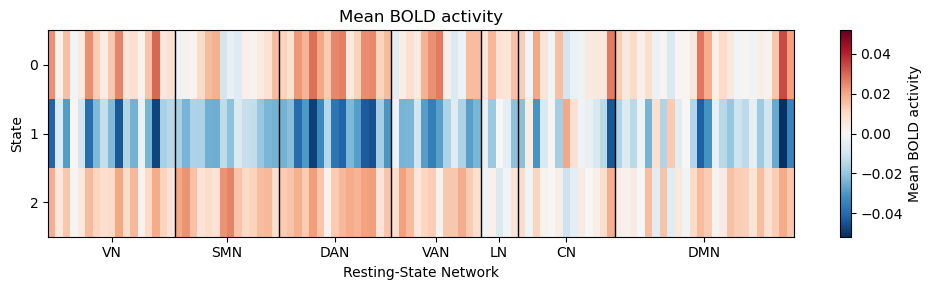

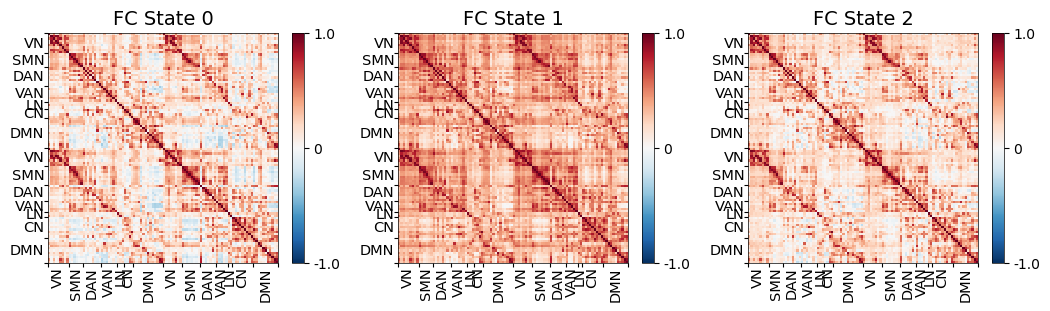

In [41]:
# Plot State means
plot_state_means(means_orig, network_labels, network_names, sort=True, figsize=(10, 3))
plt.title("Mean BOLD activity")
plt.tight_layout()
plt.show()

# Plot State FC matrices
plot_matrices([fcs_orig[k] for k in range(k_states)], network_labels=network_labels, network_names=network_names,
              titles=[f"FC State {i}" for i in range(k_states)],
              vminvmax=[[-1, 1] for k in range(k_states)], center=0,
              cmap="RdBu_r", figsize_per_matrix=(3.5, 3), sort=False)
plt.show()